# 06 — Cross-Validation & Hyperparameter Tuning (`Baseline KNN` & `Proposed DIFW-KNN`)

**Skrip CLI:** [`src/06_crossvalidation_tuning.py`](../src/06_crossvalidation_tuning.py)  
**Laporan:** [`Laporan_CrossValidation_Tuning_DIFW_KNN.md`](../Laporan_CrossValidation_Tuning_DIFW_KNN.md)

Notebook ini merepresentasikan kotak konvergensi pertama pada *flowchart* (**`Cross-Validation & Hyperparameter Tuning`**), tempat bertemunya:
- **Cabang Kiri:** `Baseline KNN` (`StandardScaler + OneHot + Euclidean`) $\rightarrow$ `20` konfigurasi $(k, \text{weights})$.
- **Cabang Kanan:** `Proposed DIFW-KNN` (`Mixed-Type Distance + Local-Context Triplet Weights + Cost-Sensitive Decision Rule`) $\rightarrow$ `20` konfigurasi *Uniform Mixed-Type* (`E2`/`E4`) dan `180` konfigurasi *Feature-Weighted DIFW-KNN* (`E3`/`E5`).

> **Protokol Anti-*Data Leakage*:** Seluruh `1.100` evaluasi *fold* dilakukan **murni di atas `Training / Development Data` (`36.168` baris)** menggunakan [`train_cv_folds.csv`](../data/processed/train_cv_folds.csv). `Hold-out Test Data` (`9.043` baris) tetap dikunci penuh hingga **Tahap 07 (`Final Model Evaluation`)**.

## 1. Ringkasan Konfigurasi Hyperparameter Terpilih (`E0` s.d. `E5`)

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
cv_dir = PROJECT_ROOT / 'outputs' / 'cv_tuning'

selected = json.loads((cv_dir / 'selected_hyperparameters.json').read_text(encoding='utf-8'))
print('=== Selected Hyperparameters (5-Fold CV) ===')
for k_mod, cfg in selected.items():
    print(f'{k_mod:6s}: {cfg}')

summary_df = pd.read_csv(cv_dir / 'cv_selected_models_summary.csv')
display(summary_df.round(4))

=== Selected Hyperparameters (5-Fold CV) ===
E0    : {'k': 5, 'weights': 'uniform', 'threshold': 0.5}
E1    : {'k': 3, 'weights': 'uniform', 'threshold': 0.5}
E1_PR : {'k': 51, 'weights': 'distance', 'threshold': 0.5}
E2    : {'k': 71, 'q': 0.5, 'neighbor_weights': 'distance', 'threshold': 0.5}
E3    : {'margin': 0.4, 'reg_lambda': 0.15, 'k': 71, 'q': 0.5, 'neighbor_weights': 'distance', 'mining_strategy': 'local_context', 'n_triplets': 24000, 'candidate_pool_size': 25, 'max_iter': 180, 'threshold': 0.5}
E4    : {'k': 71, 'q': 0.5, 'neighbor_weights': 'distance', 'c_fp': 1.0, 'c_fn': 5.0, 'threshold': 0.166667}
E5    : {'margin': 0.4, 'reg_lambda': 0.15, 'k': 71, 'q': 0.5, 'neighbor_weights': 'distance', 'mining_strategy': 'local_context', 'n_triplets': 24000, 'candidate_pool_size': 25, 'max_iter': 180, 'c_fp': 1.0, 'c_fn': 5.0, 'threshold': 0.166667}


,model_id,config_summary,accuracy_mean,precision_yes_mean,recall_yes_mean,f1_yes_mean,pr_auc_mean,roc_auc_mean,mcc_mean,g_mean_mean
0,E0,"Euclidean k=5, uniform, tau=0.50",0.8863,0.5364,0.2026,0.2938,0.2823,0.6896,0.2804,0.4444
1,E1,"Euclidean k=3, uniform, tau=0.50",0.8799,0.4729,0.2342,0.3131,0.2474,0.6664,0.2746,0.4751
2,E2,"Mixed Uniform k=71, q=0.5, tau=0.50",0.8925,0.6983,0.1428,0.2370,0.4049,0.7673,0.2830,0.3761
3,E3,"DIFW m=0.4, lam=0.15, k=71, q=0.5, tau=0.50",0.8928,0.6249,0.2087,0.3126,0.4260,0.7786,0.3184,0.4527
4,E4,"Mixed Cost k=71, q=0.5, 5:1 (tau=0.1667)",0.8539,0.3986,0.4890,0.4391,0.4049,0.7673,0.3586,0.6641
5,E5,"DIFW Lengkap m=0.4, lam=0.15, k=71, q=0.5, 5:1",0.8641,0.4320,0.5138,0.4692,0.4260,0.7786,0.3940,0.6838


## 2. Hasil Grid Search 5-Fold CV per Cabang (`Baseline`, `Mixed-Uniform`, & `Proposed DIFW-KNN`)

In [2]:
base_cv = pd.read_csv(cv_dir / 'baseline_cv_grid_results.csv')
unif_cv = pd.read_csv(cv_dir / 'mixed_uniform_cv_grid_results.csv')
difw_cv = pd.read_csv(cv_dir / 'difw_knn_cv_grid_results.csv')

print(f'Total evaluasi grid -> Baseline: {len(base_cv)} configs | Mixed-Uniform: {len(unif_cv)} configs | DIFW-KNN: {len(difw_cv)} configs')
print('\n--- Top 6 Baseline Euclidean KNN (diurutkan F1 / MCC) ---')
display(base_cv.sort_values(['f1_yes_mean', 'mcc_mean'], ascending=False).head(6)[['weights', 'k', 'accuracy_mean', 'precision_yes_mean', 'recall_yes_mean', 'f1_yes_mean', 'pr_auc_mean', 'roc_auc_mean', 'mcc_mean']].round(4))

print('\n--- Top 6 Mixed-Type Uniform (E2 & E4) ---')
display(unif_cv.head(6)[['k', 'q', 'pr_auc_mean', 'roc_auc_mean', 'e2_f1_mean', 'e2_mcc_mean', 'e4_f1_mean', 'e4_mcc_mean', 'e4_gmean_mean']].round(4))

print('\n--- Top 10 Proposed DIFW-KNN (E3 & E5) ---')
display(difw_cv.head(10)[['margin', 'reg_lambda', 'k', 'q', 'pr_auc_mean', 'roc_auc_mean', 'e3_f1_mean', 'e3_mcc_mean', 'e5_f1_mean', 'e5_mcc_mean', 'e5_gmean_mean']].round(4))

Total evaluasi grid -> Baseline: 20 configs | Mixed-Uniform: 20 configs | DIFW-KNN: 180 configs

--- Top 6 Baseline Euclidean KNN (diurutkan F1 / MCC) ---

--- Top 6 Mixed-Type Uniform (E2 & E4) ---

--- Top 10 Proposed DIFW-KNN (E3 & E5) ---


,weights,k,accuracy_mean,precision_yes_mean,recall_yes_mean,f1_yes_mean,pr_auc_mean,roc_auc_mean,mcc_mean
10,uniform,3,0.8799,0.4729,0.2342,0.3131,0.2474,0.6664,0.2746
0,distance,3,0.8753,0.4394,0.2401,0.3104,0.2709,0.6679,0.2622
1,distance,5,0.8838,0.5078,0.2113,0.2982,0.3105,0.6925,0.2750
11,uniform,5,0.8863,0.5364,0.2026,0.2938,0.2823,0.6896,0.2804
2,distance,7,0.8878,0.5563,0.1997,0.2938,0.3315,0.7092,0.2862
12,uniform,7,0.8893,0.5803,0.1945,0.2913,0.3042,0.7062,0.2912


,k,q,pr_auc_mean,roc_auc_mean,e2_f1_mean,e2_mcc_mean,e4_f1_mean,e4_mcc_mean,e4_gmean_mean
0,71,0.5,0.4049,0.7673,0.2370,0.2830,0.4391,0.3586,0.6641
1,51,0.5,0.4038,0.7635,0.2450,0.2865,0.4331,0.3509,0.6651
2,71,1.0,0.4008,0.7663,0.2393,0.2811,0.4368,0.3554,0.6665
3,51,1.0,0.3983,0.7620,0.2492,0.2873,0.4292,0.3460,0.6668
4,31,0.5,0.3977,0.7533,0.2622,0.2922,0.4187,0.3334,0.6607
5,71,0.0,0.3938,0.7661,0.2333,0.2797,0.4361,0.3547,0.6651


,margin,reg_lambda,k,q,pr_auc_mean,roc_auc_mean,e3_f1_mean,e3_mcc_mean,e5_f1_mean,e5_mcc_mean,e5_gmean_mean
0,0.4,0.15,71,0.5,0.4260,0.7786,0.3126,0.3184,0.4692,0.3940,0.6838
1,0.3,0.08,51,0.5,0.4259,0.7757,0.3215,0.3261,0.4715,0.3959,0.6931
2,0.4,0.15,51,0.5,0.4256,0.7753,0.3304,0.3326,0.4664,0.3898,0.6902
3,0.4,0.25,51,0.5,0.4248,0.7755,0.3292,0.3311,0.4705,0.3947,0.6934
4,0.5,0.25,51,0.5,0.4243,0.7759,0.3336,0.3350,0.4682,0.3919,0.6917
5,0.5,0.15,51,0.5,0.4240,0.7748,0.3344,0.3348,0.4681,0.3917,0.6935
6,0.4,0.15,71,1.0,0.4239,0.7786,0.3208,0.3251,0.4686,0.3929,0.6867
7,0.3,0.08,51,1.0,0.4237,0.7756,0.3292,0.3327,0.4699,0.3938,0.6955
8,0.3,0.08,71,0.5,0.4235,0.7803,0.3016,0.3093,0.4710,0.3959,0.6859
9,0.4,0.08,51,0.5,0.4235,0.7756,0.3312,0.3326,0.4662,0.3896,0.6910


## 3. Bobot Fitur Optimal Lintas 5 Fold CV & Sensitivitas Rasio Biaya (`Out-of-Fold`)

In [3]:
cv_weights_df = pd.read_csv(cv_dir / 'cv_optimal_feature_weights.csv')
cost_sens_df = pd.read_csv(cv_dir / 'cv_oof_cost_sensitivity.csv')

display(cv_weights_df.round(5))
display(cost_sens_df.round(4))

,feature,cv_weight_mean,cv_weight_std,uniform_prior,relative_importance
0,month,0.31145,0.00387,0.0625,4.98318
1,poutcome,0.10824,0.00376,0.0625,1.73189
2,previously_contacted,0.09687,0.00347,0.0625,1.54985
3,age,0.09060,0.00423,0.0625,1.44956
4,day,0.08909,0.00428,0.0625,1.42542
5,campaign,0.06681,0.00146,0.0625,1.06890
6,pdays_recency,0.06191,0.00358,0.0625,0.99054
7,balance,0.05857,0.00483,0.0625,0.93708
8,contact,0.05070,0.00235,0.0625,0.81113
9,housing,0.02852,0.00268,0.0625,0.45629


,c_fn_ratio,threshold,accuracy,precision_yes,recall_yes,f1_yes,mcc,g_mean,mean_cost,cost_reduction_pct
0,1.00,0.5000,0.8928,0.6245,0.2087,0.3128,0.3185,0.4530,0.1072,0.0000
1,2.00,0.3333,0.8837,0.5035,0.4042,0.4484,0.3872,0.6187,0.1860,6.9047
2,3.00,0.2500,0.8763,0.4704,0.4569,0.4635,0.3937,0.6525,0.2508,14.2317
3,4.00,0.2000,0.8720,0.4556,0.4838,0.4693,0.3968,0.6684,0.3092,19.6868
4,5.00,0.1667,0.8641,0.4319,0.5138,0.4693,0.3940,0.6840,0.3634,23.8955
5,7.55,0.1170,0.8217,0.3476,0.5977,0.4396,0.3601,0.7134,0.4865,31.8203


## 4. Visualisasi Kurva Hyperparameter Tuning, Heatmap $(m, \lambda)$, & Pemenang 5-Fold CV

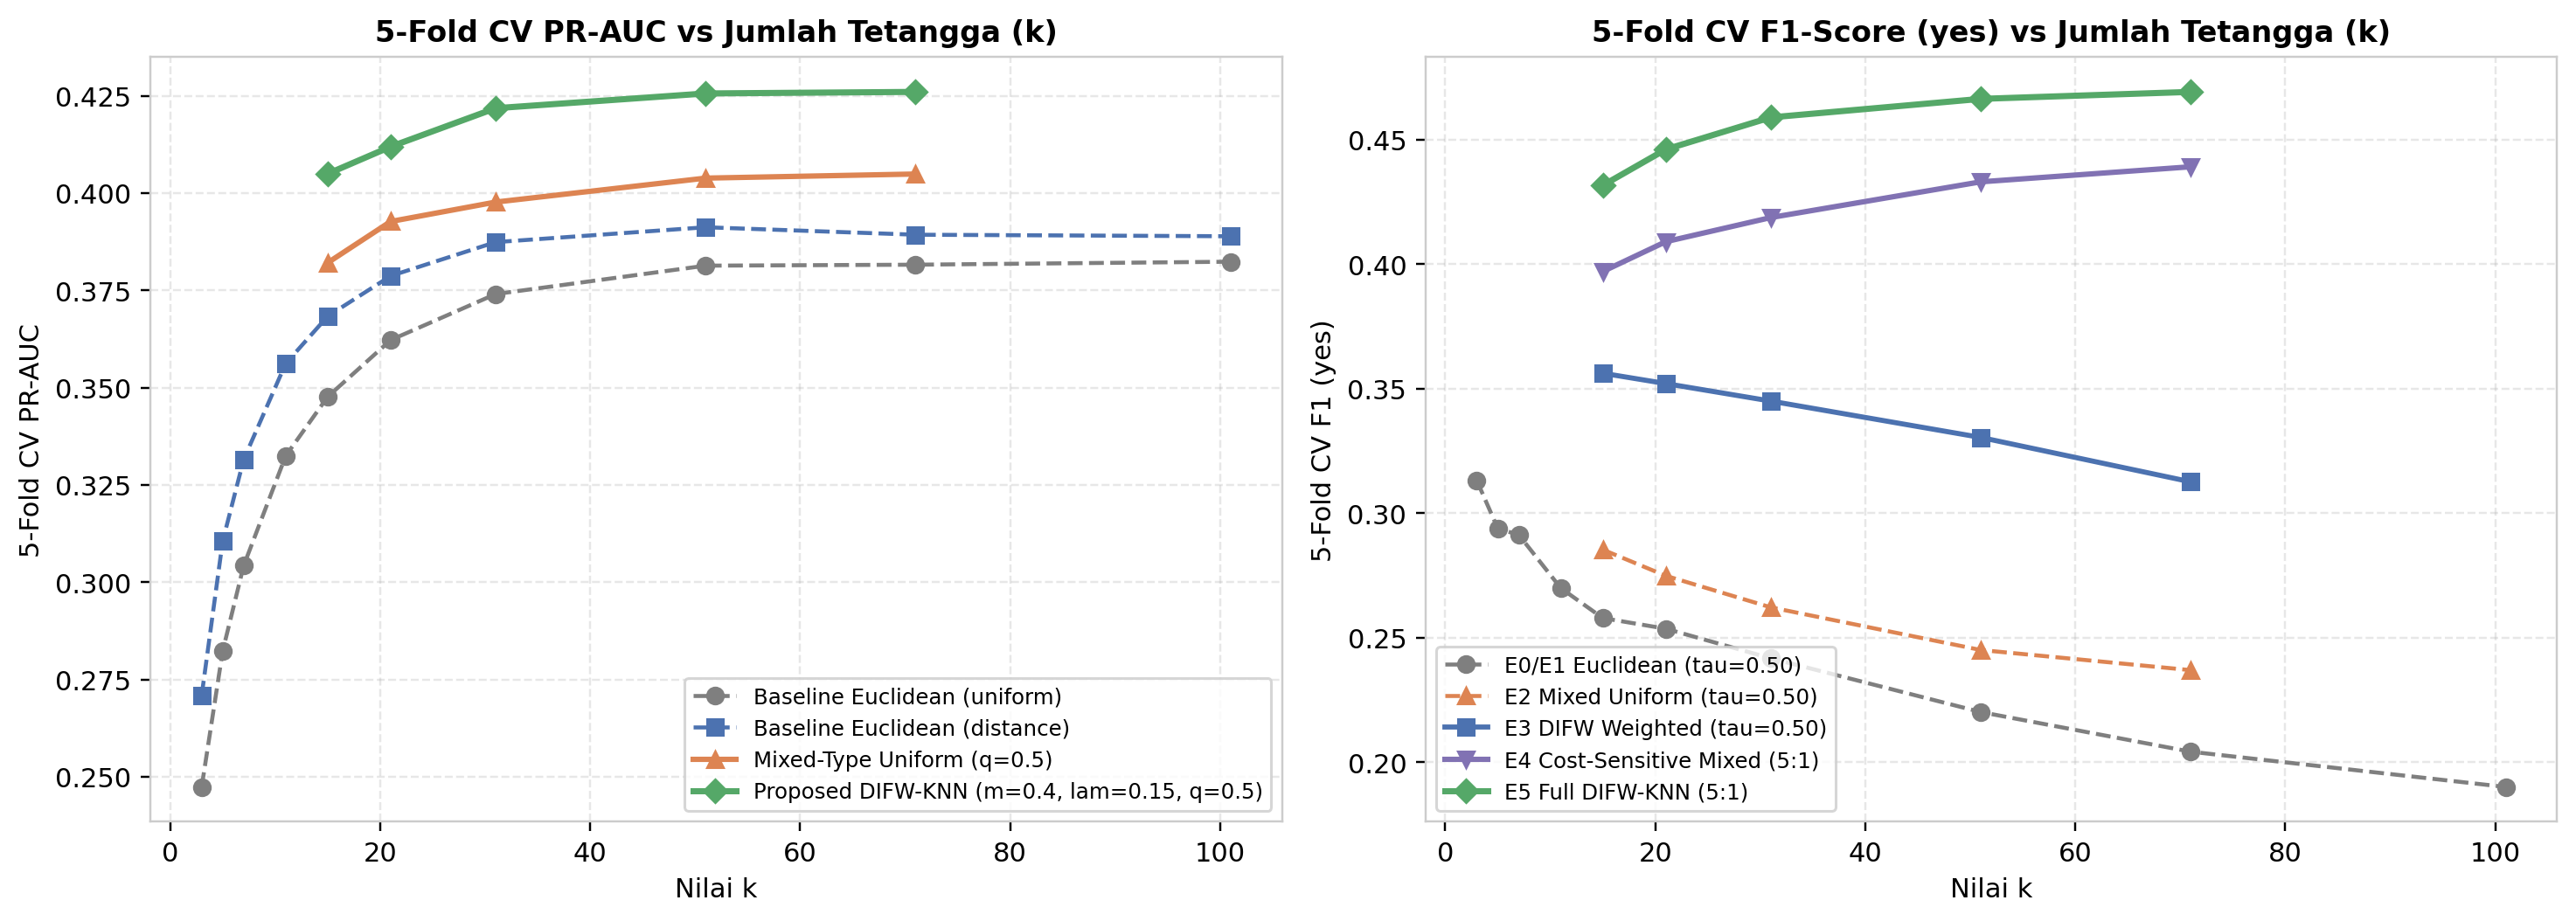

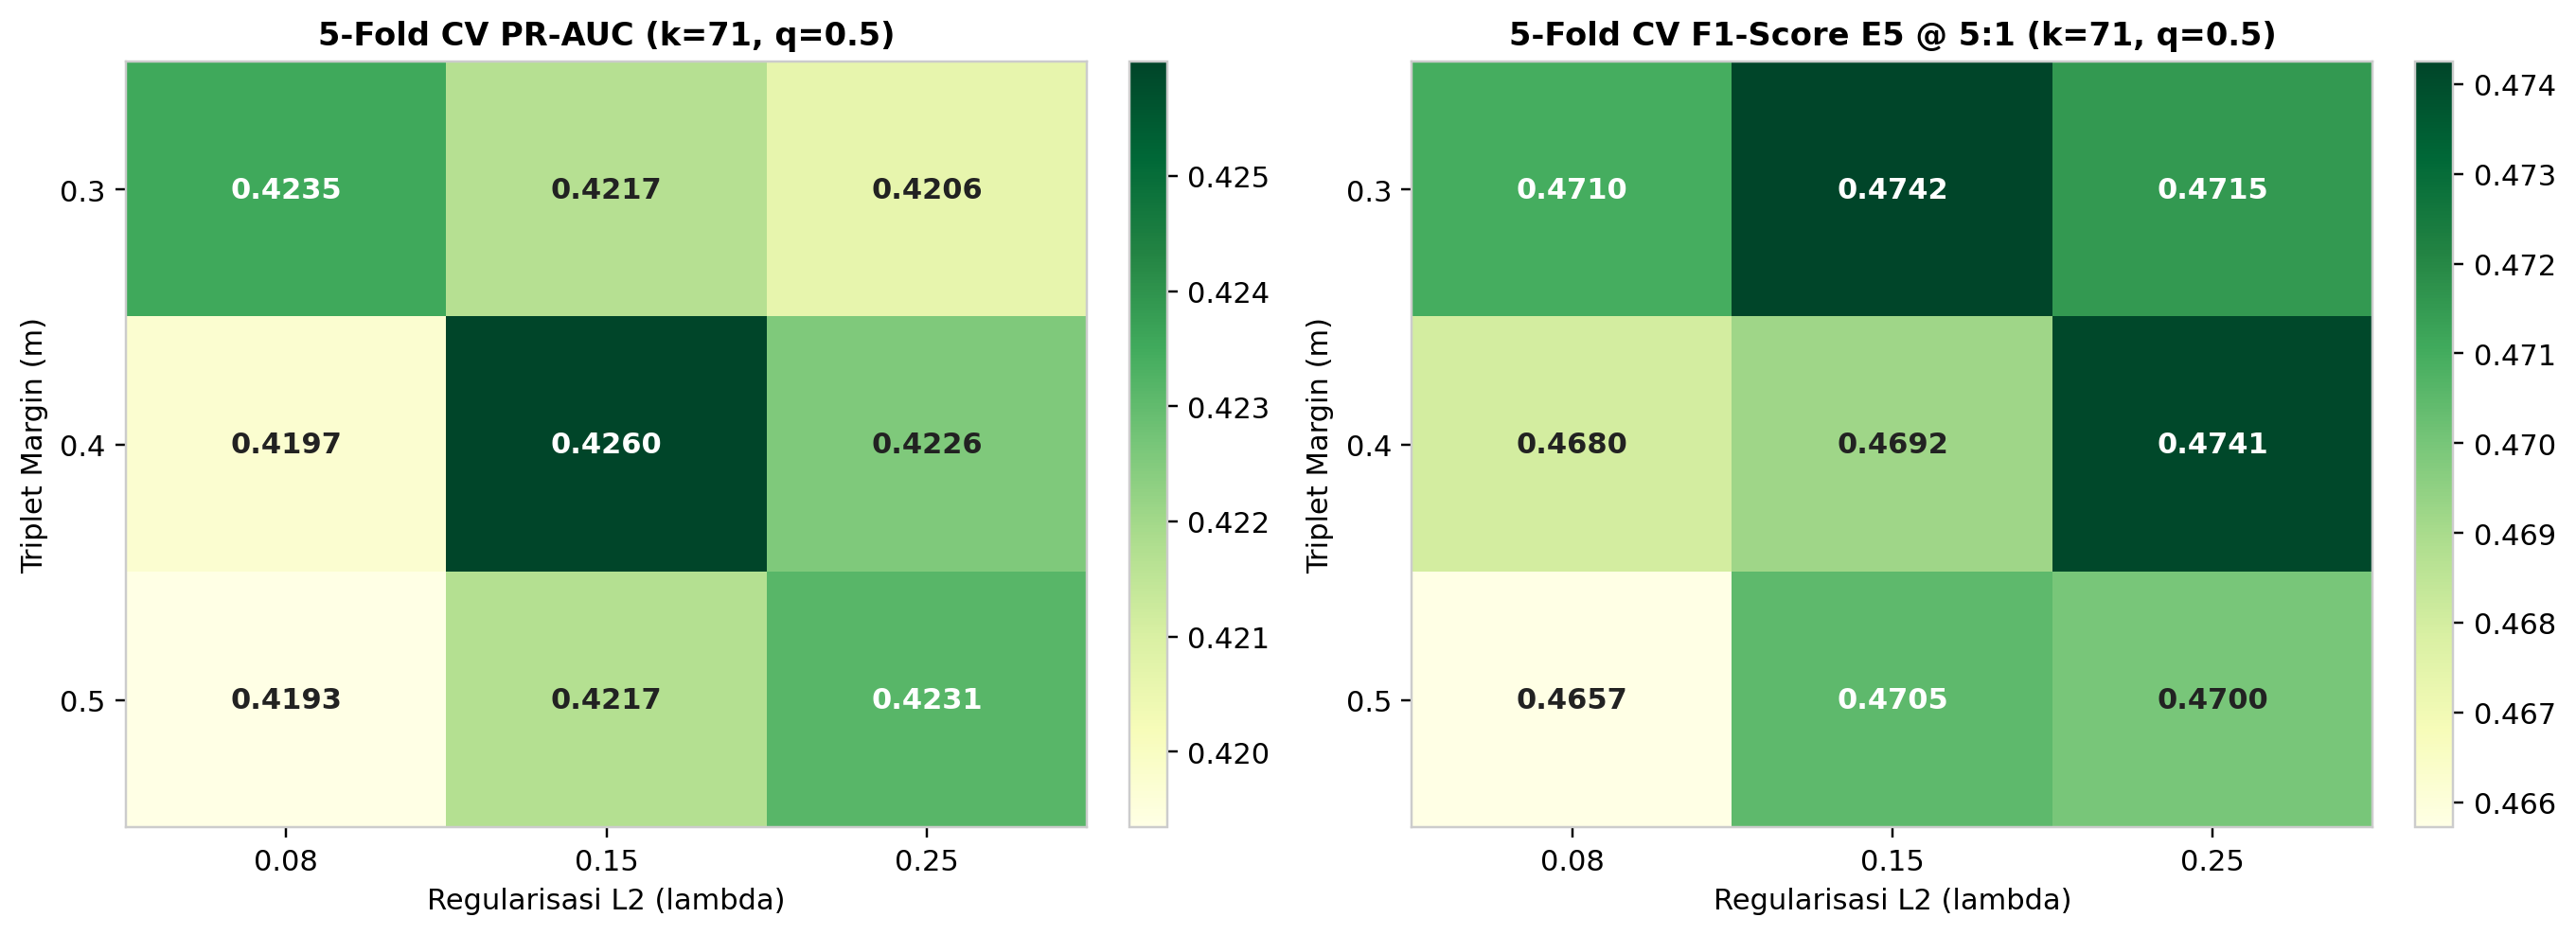

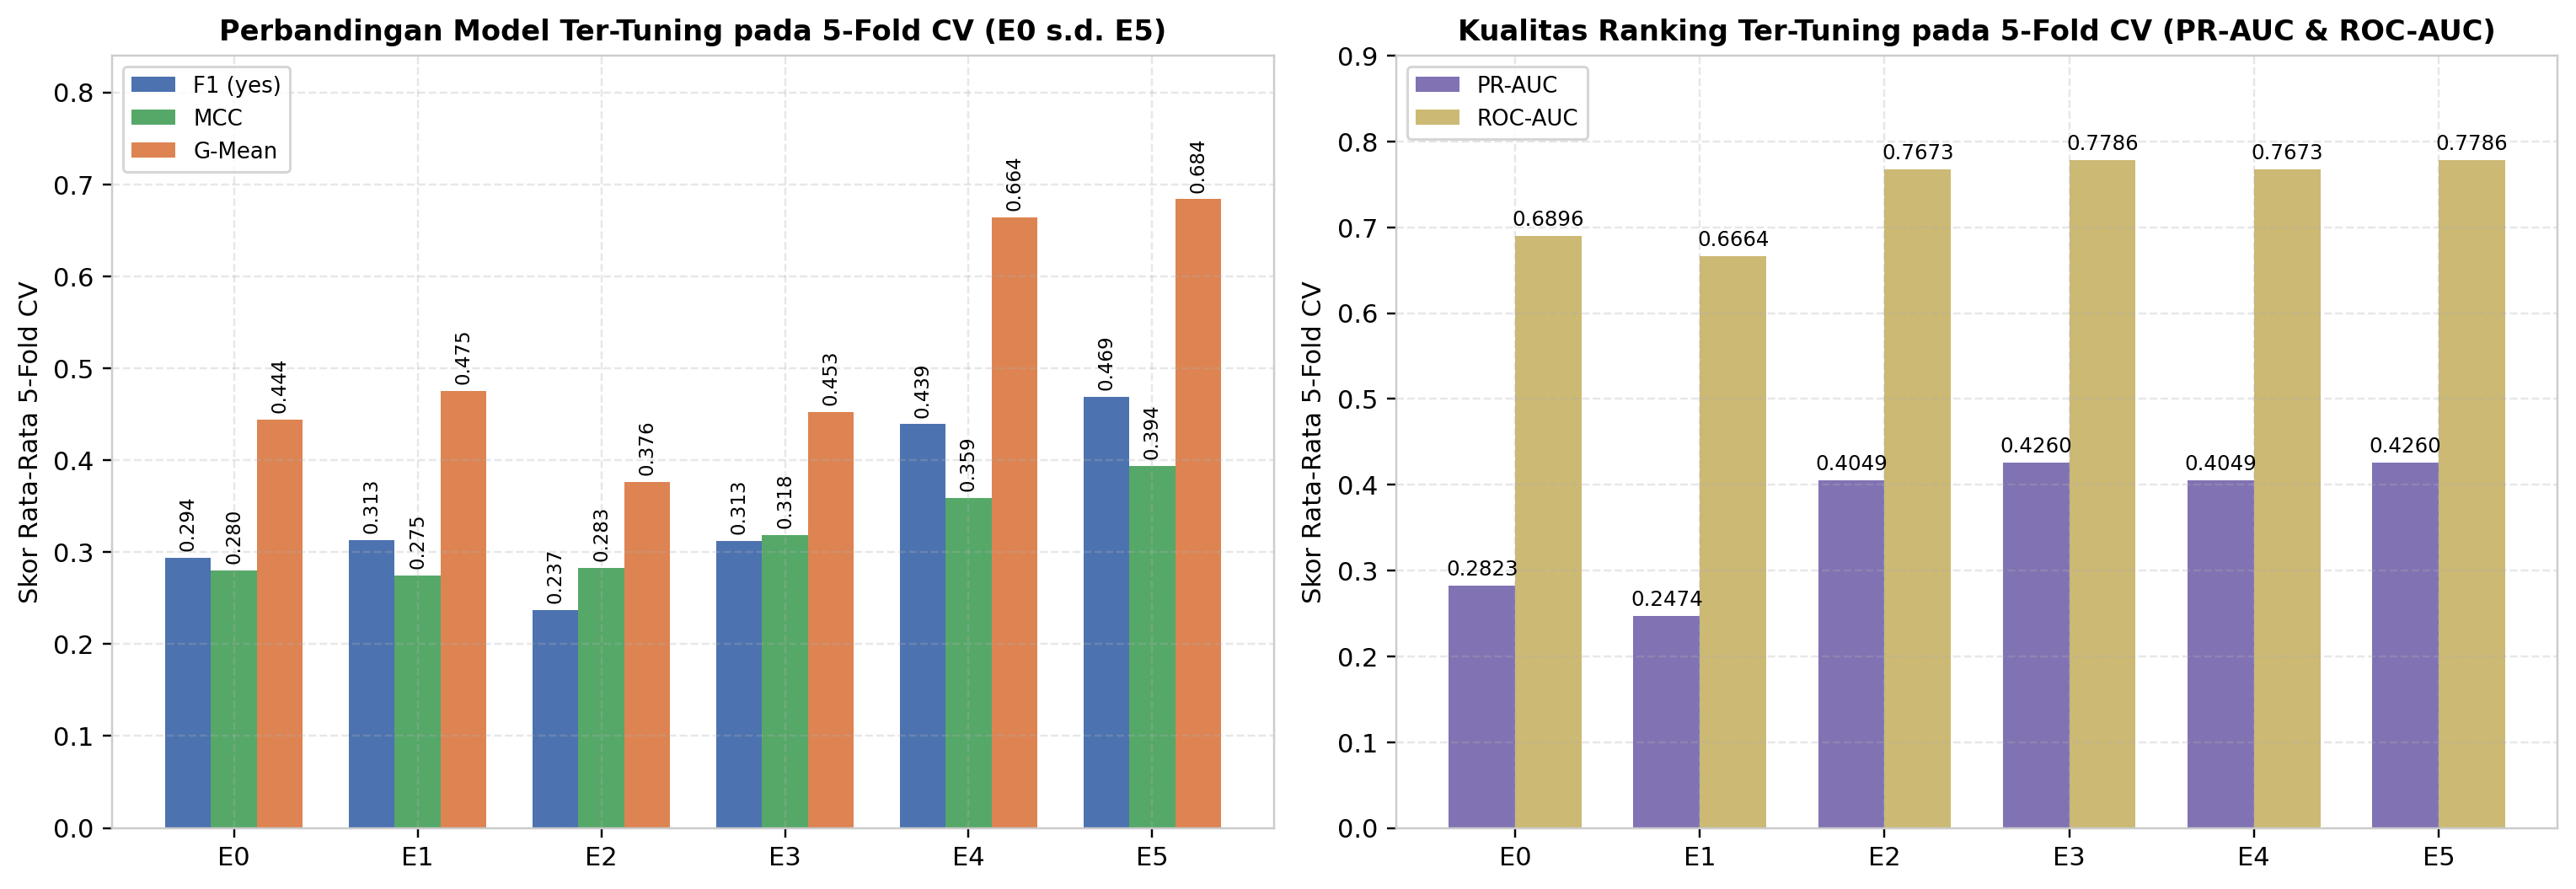

In [4]:
fig_dir = cv_dir / 'figures'
for fname in [
    '01_cv_k_curves_baseline_vs_difw.png',
    '02_difw_margin_lambda_heatmaps.png',
    '03_tuned_cv_winners_e0_to_e5.png',
]:
    display(Image(fig_dir / fname))